# Binary classification

In [31]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from src.utils import fs_utils

project_root, data_dir = fs_utils.get_data_dir()
sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)
project_root, data_dir

(PosixPath('/opt/pc-hardware-analysis'),
 PosixPath('/opt/pc-hardware-analysis/data'))

## Subgroup size

### Data analysis

In [2]:
def load_vulkan_feature_frame() -> pd.DataFrame:
    def read_json(path: Path) -> dict:
        with path.open("r", encoding="utf-8") as handle:
            data = json.load(handle)

        profiles = data.get("profiles", {})
        gpu_key = next((k for k in profiles if k.startswith("VP_GPUINFO_")), None)

        if not gpu_key:
            raise ValueError("No GPU profile found")

        gpu_info = profiles.get(gpu_key)
        device_props = data.get("capabilities").get("device").get("properties")
        vk_physical_device_limits = device_props.get("VkPhysicalDeviceProperties").get(
            "limits"
        )
        return {
            "reportId": path.stem,
            "apiVersion": gpu_info.get("api-version"),
            "label": gpu_info.get("label"),
            "subgroupSize": device_props.get("VkPhysicalDeviceSubgroupProperties").get(
                "subgroupSize"
            ),
            "bufferImageGranularity": vk_physical_device_limits.get(
                "bufferImageGranularity"
            ),
            "lineWidthGranularity": vk_physical_device_limits.get(
                "lineWidthGranularity"
            ),
            "maxBoundDescriptorSets": vk_physical_device_limits.get(
                "maxBoundDescriptorSets"
            ),
        }

    rows = [
        read_json(path)
        for path in sorted((data_dir / "vulkan-profiles").glob("**/*.json"))
    ]
    return pd.DataFrame(rows).sort_values(["reportId"]).reset_index(drop=True)


vulkan_frame = load_vulkan_feature_frame()
display(vulkan_frame)
display(vulkan_frame.describe())

,reportId,apiVersion,label,subgroupSize,bufferImageGranularity,lineWidthGranularity,maxBoundDescriptorSets
0,10934,1.2.170,NVIDIA GeForce RTX 3090 driver 470.5.0.0 on Wi...,32,1024,0.062500,32
1,10993,1.2.168,NVIDIA GeForce RTX 3080 driver 465.89.0.0 on W...,32,1024,0.062500,32
2,11121,1.2.168,NVIDIA GeForce RTX 3080 driver 466.11.0.0 on W...,32,1024,0.062500,32
3,11141,1.2.168,NVIDIA GeForce RTX 3090 driver 465.24.2.0 on U...,32,1024,0.062500,32
4,11209,1.2.168,NVIDIA GeForce RTX 3080 driver 465.24.2.0 on F...,32,1024,0.062500,32
...,...,...,...,...,...,...,...
261,49142,1.4.312,NVIDIA GeForce RTX 4080 driver 580.159.3.0 on ...,32,1024,0.062500,32
262,49144,1.4.348,Intel(R) Arc(TM) A770 Graphics driver 0.406.60...,32,1,0.007812,32
263,49180,1.4.312,NVIDIA GeForce RTX 4080 driver 580.159.3.0 on ...,32,1024,0.062500,32
264,49185,1.4.341,NVIDIA GeForce RTX 5090 driver 610.47.0.0 on W...,32,1024,0.062500,32


,subgroupSize,bufferImageGranularity,lineWidthGranularity,maxBoundDescriptorSets
count,266.000000,266.000000,266.000000,266.000000
mean,34.646617,731.714286,0.056567,31.812030
std,8.830646,463.015442,0.029973,2.078281
min,32.000000,1.000000,0.007812,8.000000
25%,32.000000,1.000000,0.062500,32.000000
50%,32.000000,1024.000000,0.062500,32.000000
75%,32.000000,1024.000000,0.062500,32.000000
max,64.000000,1024.000000,0.125000,32.000000


reportId
10934    1
10993    1
11121    1
11141    1
11209    1
        ..
49142    1
49144    1
49180    1
49185    1
49229    1
Name: count, Length: 266, dtype: int64

True

apiVersion
1.4.312    23
1.4.303    22
1.4.329    19
1.3.224    13
1.4.325    13
1.2.175    11
1.3.236     8
1.3.277     8
1.3.289     8
1.2.168     7
1.3.205     7
1.3.242     7
1.4.308     7
1.3.194     6
1.4.348     6
1.3.278     5
1.3.280     5
1.3.295     5
1.4.311     5
1.4.347     5
1.4.335     5
1.3.267     4
1.3.302     4
1.4.341     4
1.4.340     4
1.2.186     3
1.3.250     3
1.3.260     3
1.4.307     3
1.4.318     3
1.4.328     3
1.3.228     2
1.3.231     2
1.3.235     2
1.3.248     2
1.3.271     2
1.3.273     2
1.4.305     2
1.4.309     2
1.4.315     2
1.4.351     2
1.2.170     1
1.2.194     1
1.2.201     1
1.3.230     1
1.3.237     1
1.3.240     1
1.3.218     1
1.3.259     1
1.1.0       1
1.3.0       1
1.3.263     1
1.3.276     1
1.4.313     1
1.4.323     1
1.4.333     1
1.4.344     1
1.3.286     1
Name: count, dtype: int64

label
Microsoft Corporation Subsystem for Android(TM) driver 537.42.0.0 on Android 13.0    2
NVIDIA GeForce RTX 3090 driver 470.5.0.0 on Windows 10                               1
NVIDIA GeForce RTX 3080 driver 465.89.0.0 on Windows 10                              1
NVIDIA GeForce RTX 3080 driver 466.11.0.0 on Windows 10                              1
NVIDIA GeForce RTX 3090 driver 465.24.2.0 on Ubuntu 20.10                            1
                                                                                    ..
NVIDIA GeForce RTX 4080 driver 580.159.3.0 on Ubuntu 24.04                           1
Intel(R) Arc(TM) A770 Graphics driver 0.406.609 on Windows 11                        1
NVIDIA GeForce RTX 4080 driver 580.159.3.0 on Ubuntu 26.04                           1
NVIDIA GeForce RTX 5090 driver 610.47.0.0 on Windows 11                              1
NVIDIA GeForce RTX 5090 driver 595.71.5.0 on Linuxmint 22.3                          1
Name: count, Length: 265, dtype: int6

subgroupSize
32    244
64     22
Name: count, dtype: int64

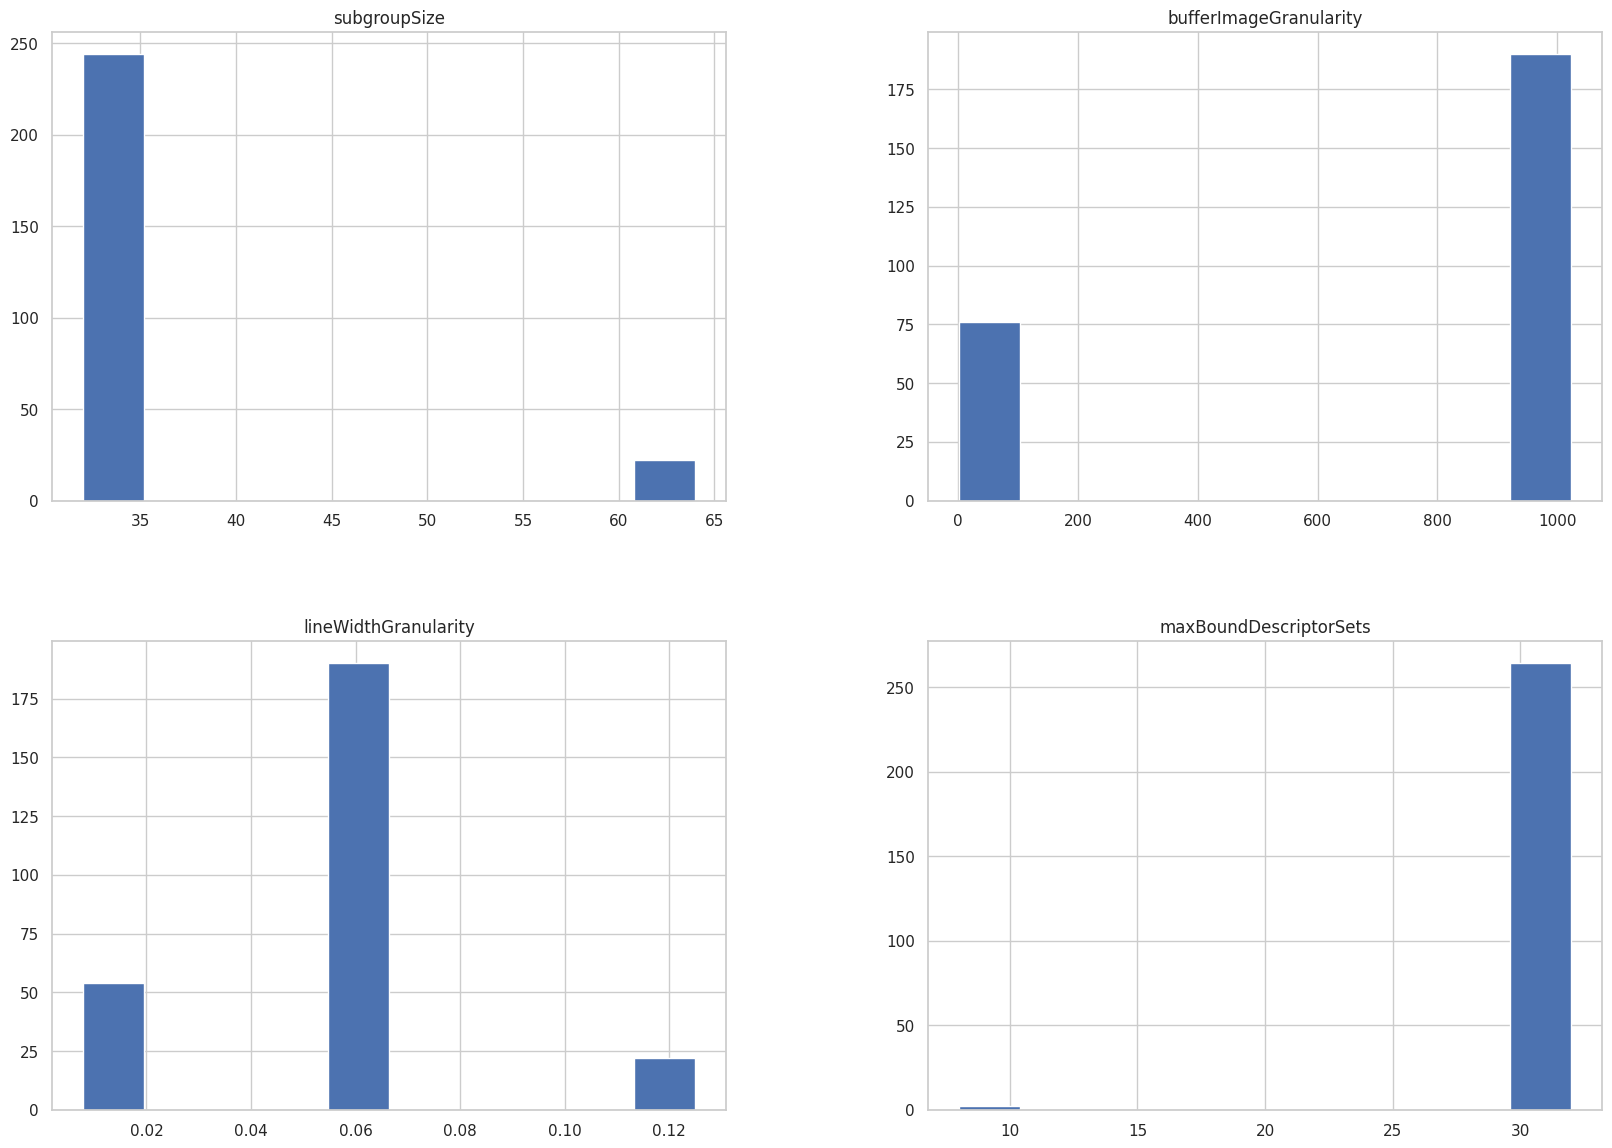

In [ ]:
target_column_train = "subgroupSize"


def show_field_details(df: pd.DataFrame):
    display(df["reportId"].value_counts())
    display(df["reportId"].is_unique)
    display(df["apiVersion"].value_counts())
    display(df["label"].value_counts())
    display(df[target_column_train].value_counts())
    df.hist(figsize=(20, 14))


show_field_details(vulkan_frame)

In [4]:
pd.crosstab(index=vulkan_frame["label"], columns=vulkan_frame["apiVersion"])

apiVersion,1.1.0,1.2.168,1.2.170,1.2.175,1.2.186,1.2.194,...,1.4.340,1.4.341,1.4.344,1.4.347,1.4.348,1.4.351
label,,,,,,,,,,,,,
AMD Radeon 780M Graphics (RADV PHOENIX) driver 26.0.3 on Ubuntu 26.04,0,0,0,0,0,0,...,0,0,0,0,0,0
AMD Radeon 780M Graphics (RADV PHOENIX) driver 26.0.5 on Ubuntu 24.04,0,0,0,0,0,0,...,0,0,0,0,0,0
AMD Radeon 780M Graphics (RADV PHOENIX) driver 26.0.6 on Ubuntu 24.04,0,0,0,0,0,0,...,0,0,0,0,0,0
AMD Radeon 780M Graphics (RADV PHOENIX) driver 26.1.0 on Ubuntu 24.04,0,0,0,0,0,0,...,0,0,0,0,1,0
AMD Radeon RX 7900 GRE (RADV NAVI31) driver 26.0.4 on Debian unknown,0,0,0,0,0,0,...,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
NVIDIA GeForce RTX 5090 driver 595.71.5.0 on Freebsd 15.0,0,0,0,0,0,0,...,0,0,0,0,0,0
NVIDIA GeForce RTX 5090 driver 595.71.5.0 on Linuxmint 22.3,0,0,0,0,0,0,...,0,0,0,0,0,0
NVIDIA GeForce RTX 5090 driver 596.36.0.0 on Windows 11,0,0,0,0,0,0,...,0,0,0,0,0,0


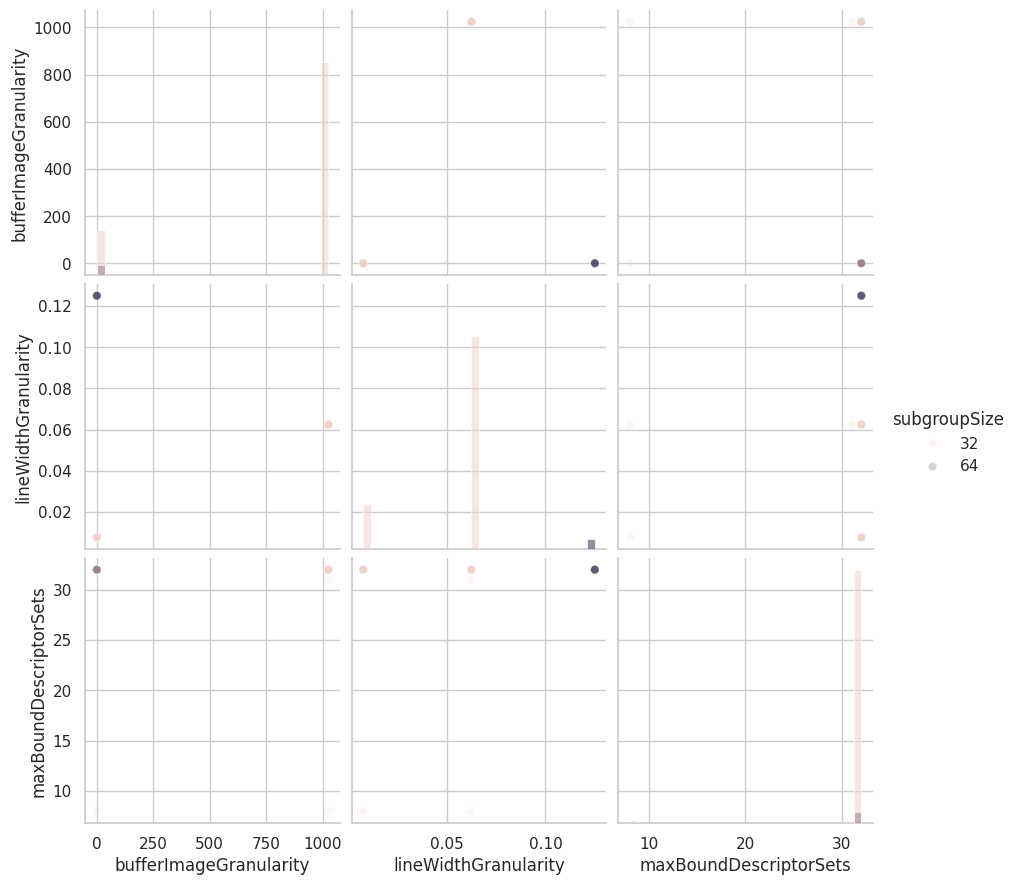

In [ ]:
n_samples_to_plot = 150
columns = ["bufferImageGranularity", "lineWidthGranularity", "maxBoundDescriptorSets"]
_ = sns.pairplot(
    data=vulkan_frame[:n_samples_to_plot],
    vars=columns,
    hue=target_column_train,
    plot_kws={"alpha": 0.2},
    height=3,
    diag_kind="hist",
    diag_kws={"bins": 30},
)

In [ ]:
display(vulkan_frame.dtypes)
data = vulkan_frame.drop(
    columns=[target_column_train, "reportId", "apiVersion", "label"]
)
display(data.columns)
data.dtypes.unique()

reportId                      str
apiVersion                    str
label                         str
subgroupSize                int64
bufferImageGranularity      int64
lineWidthGranularity      float64
maxBoundDescriptorSets      int64
dtype: object

Index(['bufferImageGranularity', 'lineWidthGranularity', 'maxBoundDescriptorSets'], dtype='str')

array([dtype('int64'), dtype('float64')], dtype=object)

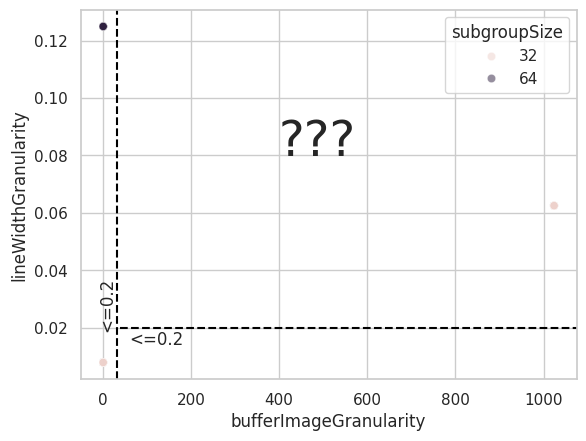

In [ ]:
def show_data_points_distribution(
    df: pd.DataFrame, axvline_limit: float, axhline_limit: float
):
    sns.scatterplot(
        x="bufferImageGranularity",
        y="lineWidthGranularity",
        data=df,
        hue=target_column_train,
        alpha=0.5,
    )

    plt.axvline(x=axvline_limit, ymin=0, ymax=1, color="black", linestyle="--")
    plt.axhline(y=axhline_limit, xmin=0.08, xmax=1, color="black", linestyle="--")

    plt.annotate("<=0.2", (-10, 0.02), rotation=90, fontsize=12)
    plt.annotate("<=0.2", (60, 0.014), fontsize=12)
    _ = plt.annotate("???", (400, 0.08), fontsize=35)


buf_img_granularity_limit = 32
line_width_granularity_limit = 0.02
show_data_points_distribution(
    vulkan_frame[:n_samples_to_plot],
    buf_img_granularity_limit,
    line_width_granularity_limit,
)

### K-nearest neighbors

In [ ]:
target = vulkan_frame[target_column_train]


def build_kneighbors_model(df: pd.DataFrame, target_column: pd.Series):
    model = KNeighborsClassifier()
    return model.fit(df, target_column)


kneighbors_model = build_kneighbors_model(data, target)
kneighbors_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [35]:
def kneighbors_predict_on_same_dataset(model: KNeighborsClassifier, df: pd.DataFrame):
    target_predicted: np.ndarray = model.predict(df)
    display(target_predicted[:5])
    display(np.where(target_predicted == 64))
    display(vulkan_frame.loc[target == 64])
    display((target == target_predicted).all())
    return target_predicted


kneighbors_target_predicted = kneighbors_predict_on_same_dataset(kneighbors_model, data)

array([32, 32, 32, 32, 32])

(array([131, 133, 134, 141, 144, 147, 153, 156, 157, 162, 167, 168, 169,
        171, 177, 194, 227, 232, 233, 238, 249, 258]),)

,reportId,apiVersion,label,subgroupSize,bufferImageGranularity,lineWidthGranularity,maxBoundDescriptorSets
131,37398,1.3.302,AMD Radeon RX 9070 XT driver 2.0.331 on Window...,64,1,0.125,32
133,37437,1.3.302,AMD Radeon RX 9070 XT driver 2.0.331 on Window...,64,1,0.125,32
134,37972,1.4.308,AMD Radeon RX 9070 XT driver 2.0.341 on Ubuntu...,64,1,0.125,32
141,38575,1.4.305,AMD Radeon RX 9070 XT (RADV GFX1201) driver 25...,64,1,0.125,32
144,38798,1.4.308,AMD Radeon RX 9070 XT driver 2.0.342 on Window...,64,1,0.125,32
147,38876,1.4.308,AMD Radeon RX 9070 XT driver 2.0.342 on Window...,64,1,0.125,32
153,39448,1.4.308,AMD Radeon RX 9060 XT driver 2.0.342 on Window...,64,1,0.125,32
156,39799,1.4.313,AMD Radeon RX 9070 XT driver 2.0.349 on Arch u...,64,1,0.125,32
157,39800,1.3.302,AMD Radeon RX 9070 XT driver 2.0.331 on Arch u...,64,1,0.125,32
162,39986,1.3.302,AMD Radeon RX 9070 XT driver 2.0.331 on Manjar...,64,1,0.125,32


True

In [36]:
def kneighbors_evaluate_accuracy(
    model: KNeighborsClassifier, train_data: pd.DataFrame, target_predicted: pd.Series
):
    print(
        "Number of correct prediction: "
        f"{(target == target_predicted).sum()} / {len(target)}"
    )
    print((target == target_predicted).mean())
    accuracy = model.score(train_data, target)
    model_name = model.__class__.__name__
    print(f"The test accuracy using a {model_name} is {accuracy:.3f}")


kneighbors_evaluate_accuracy(kneighbors_model, data, kneighbors_target_predicted)

Number of correct prediction: 266 / 266
1.0
The test accuracy using a KNeighborsClassifier is 1.000


### Logistic regression

In [32]:
data_train, data_test, target_train, target_test = train_test_split(
    data, target, random_state=42, test_size=0.25
)
display(data_train.shape, data_test.shape, target_train.shape, target_test.shape)


def build_logistic_regression_model(
    df_train: pd.DataFrame, target_column_train: pd.Series
):
    model = LogisticRegression()
    return model.fit(df_train, target_column_train)


logistic_regression_model = build_logistic_regression_model(data, target)
logistic_regression_model

(199, 3)

(67, 3)

(199,)

(67,)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [33]:
accuracy = logistic_regression_model.score(data_test, target_test)
print(f"Accuracy of logistic regression: {accuracy:.3f}")

Accuracy of logistic regression: 0.910


## PyTorch classifier

In [ ]:
def run_torch_classifier(
    X: pd.DataFrame, y: pd.Series, seed: int = 7, epochs: int = 250
):
    np.random.seed(seed)
    torch.manual_seed(seed)
    scaled_x = StandardScaler().fit_transform(X)
    x_tensor = torch.tensor(scaled_x, dtype=torch.float32)
    y_tensor = torch.tensor(
        y.to_numpy(dtype=np.float32).reshape(-1, 1), dtype=torch.float32
    )

    model = torch.nn.Sequential(
        torch.nn.Linear(x_tensor.shape[1], min(16, max(4, x_tensor.shape[1]))),
        torch.nn.ReLU(),
        torch.nn.Linear(min(16, max(4, x_tensor.shape[1])), 1),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    loss_history: list[float] = []

    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(x_tensor)
        loss = loss_fn(logits, y_tensor)
        loss.backward()
        optimizer.step()
        loss_history.append(float(loss.detach().cpu().item()))

    probabilities = torch.sigmoid(model(x_tensor)).detach().cpu().numpy().reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "name": "dense_classifier",
        "framework": "PyTorch",
        "task": "classification",
        "accuracy": float(accuracy_score(y.to_numpy(dtype=int), predictions)),
        "predictions": predictions,
        "details": {
            "loss_history": loss_history,
            "probabilities": probabilities.tolist(),
        },
    }


epochs = 50
y: pd.Series = target
seed = 7
np.random.seed(seed)
torch.manual_seed(seed)
scaled_x = StandardScaler().fit_transform(data)
x_tensor = torch.tensor(scaled_x, dtype=torch.float32)
y_tensor = torch.tensor(
    y.to_numpy(dtype=np.float32).reshape(-1, 1), dtype=torch.float32
)

model = torch.nn.Sequential(
    torch.nn.Linear(x_tensor.shape[1], min(16, max(4, x_tensor.shape[1]))),
    torch.nn.ReLU(),
    torch.nn.Linear(min(16, max(4, x_tensor.shape[1])), 1),
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
loss_fn = torch.nn.BCEWithLogitsLoss()
loss_history: list[float] = []

for _ in range(epochs):
    optimizer.zero_grad()
    logits = model(x_tensor)
    loss = loss_fn(logits, y_tensor)
    loss.backward()
    optimizer.step()
    loss_history.append(float(loss.detach().cpu().item()))

probabilities = torch.sigmoid(model(x_tensor)).detach().cpu().numpy().reshape(-1)
predictions = (probabilities >= 0.5).astype(int)
display(model)
{
    "name": "dense_classifier",
    "framework": "PyTorch",
    "task": "classification",
    "accuracy": float(accuracy_score(y.to_numpy(dtype=int), predictions)),
    "predictions": predictions,
    "details": {"loss_history": loss_history, "probabilities": probabilities.tolist()},
}

Sequential(
  (0): Linear(in_features=3, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
)

{'name': 'dense_classifier',
 'framework': 'PyTorch',
 'task': 'classification',
 'accuracy': 0.0,
 'predictions': array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1